In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))
ART = ROOT / "artifacts"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from plotting import series_styles, new_figure

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

def es(v, d=4):
    """Numero con formato de Colombia: punto de miles y coma decimal."""
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return ""
    if isinstance(v, (int, np.integer)):
        return f"{int(v):,}".replace(",", ".")
    s = f"{float(v):,.{d}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")

def tabla(df, d=4, enteros=()):
    out = df.copy()
    for c in out.columns:
        if c in enteros:
            out[c] = out[c].map(lambda v: es(int(v)) if pd.notna(v) else "")
        elif pd.api.types.is_float_dtype(out[c]):
            out[c] = out[c].map(lambda v: es(v, d))
        elif pd.api.types.is_integer_dtype(out[c]):
            out[c] = out[c].map(es)
    display(out.style.hide(axis="index"))

def figura(ruta, ancho=None):
    display(Image(filename=str(ruta), width=ancho))

# 9. Comparación de resultados

Este capítulo reúne en un solo lugar la comparación que pide el enunciado: una tabla con media, desviación estándar e intervalo de confianza de cada métrica por entorno, modelo y estrategia de codificación, los tiempos de entrenamiento y predicción con memoria pico, las barras comparativas de tiempo y las ablaciones de dimensión del hashing, cruces de variables, profundidad del MLP y ponderación de clases. Con las ablaciones se responde además la pregunta P2 y se contrasta la hipótesis H2.

Las curvas que pide el enunciado ya se presentaron donde se analizan: las ROC y PR superpuestas y las de calibración en las secciones 6.1 y 6.2, las curvas de aprendizaje en la sección 4.4, y las de escalamiento y el punto de cruce en el capítulo 7. Aquí se comparan los resultados entre sí.

In [2]:
ABL = ART / "ablation"
runs_abl = pd.read_csv(ABL / "runs.csv")
contr = pd.read_csv(ABL / "contrastes_vs_base.csv")
T4 = 2.776  # t(0,975; 4)
def resumen(df, metricas=("roc_auc", "pr_auc", "log_loss", "brier", "ece")):
    out = {}
    for m in metricas:
        mu, sd = df[m].mean(), df[m].std(ddof=1)
        out[m] = mu; out[m + "_de"] = sd
        out[m + "_ic"] = f"[{es(mu - T4 * sd / np.sqrt(len(df)))}; {es(mu + T4 * sd / np.sqrt(len(df)))}]"
    return out

## 9.1 Tabla comparativa por entorno, modelo y codificación

Cada fila resume 5 semillas. El IC 95 % usa la distribución $t$ con 4 grados de libertad, $\bar x \pm t_{0{,}975;\,4}\, s/\sqrt 5$. Las filas de scikit-learn del experimento principal se evalúan sobre 202.511 filas del día 30, las de Spark sobre el día 30 completo (4.218.938 filas) y las de la ablación sobre 200.000 filas del día 30, de modo que las comparaciones finas solo son válidas dentro de cada bloque; entre entornos, el capítulo 6 usa la prueba de DeLong sobre las mismas filas.

In [3]:
filas = []
sk = pd.read_csv(ART / "sklearn" / "runs.csv").query("tier == 2000000")
for m, nom in (("mlp", "MLP (50)"), ("histgb", "HistGB"), ("sgd", "SGD (logística)")):
    filas.append({"entorno": "scikit-learn", "modelo": nom, "codificación": "combinada: hashing 2^12 + frecuencia + TE",
                  "filas de entrenamiento": 1601694, **resumen(sk[sk["model"] == m])})
spm = pd.read_csv(ART / "stats" / "spark_metricas_por_corrida.csv")
info = {"lr": ("LR", "hashing 2^12 + índice", 32377421), "mlp": ("MLP (100)", "hashing 2^9 + índice", 300000),
        "gbt": ("GBT", "solo índice (5 de baja cardinalidad)", 1000000)}
for m, (nom, cod, n) in info.items():
    filas.append({"entorno": "Spark local", "modelo": nom, "codificación": cod, "filas de entrenamiento": n,
                  **resumen(spm[spm["model"] == m])})
for c, cod in (("base", "combinada (ablación)"), ("solo_hashing", "solo hashing 2^12"),
               ("solo_target_encoding", "solo target encoding"), ("solo_frecuencia", "solo frecuencia")):
    filas.append({"entorno": "scikit-learn", "modelo": "MLP (50)", "codificación": cod, "filas de entrenamiento": 200000,
                  **resumen(runs_abl[runs_abl["config"] == c])})
M = pd.DataFrame(filas)
tabla(M[["entorno", "modelo", "codificación", "filas de entrenamiento", "roc_auc", "roc_auc_de", "roc_auc_ic",
         "pr_auc", "log_loss", "brier", "ece"]].rename(columns={
    "roc_auc": "ROC AUC", "roc_auc_de": "DE", "roc_auc_ic": "IC 95 % ROC AUC", "pr_auc": "PR AUC",
    "log_loss": "log loss", "brier": "Brier", "ece": "ECE"}), d=4, enteros=("filas de entrenamiento",))

entorno,modelo,codificación,filas de entrenamiento,ROC AUC,DE,IC 95 % ROC AUC,PR AUC,log loss,Brier,ECE
scikit-learn,MLP (50),combinada: hashing 2^12 + frecuencia + TE,1.601.694,"0,7306","0,0015","[0,7288; 0,7325]","0,3560","0,4067","0,1270","0,0089"
scikit-learn,HistGB,combinada: hashing 2^12 + frecuencia + TE,1.601.694,"0,7288","0,0004","[0,7283; 0,7293]","0,3542","0,4071","0,1272","0,0075"
scikit-learn,SGD (logística),combinada: hashing 2^12 + frecuencia + TE,1.601.694,"0,7265","0,0004","[0,7260; 0,7270]","0,3506","0,4085","0,1275","0,0073"
Spark local,LR,hashing 2^12 + índice,32.377.421,"0,7157","0,0000","[0,7157; 0,7157]","0,3297","0,4131","0,1286","0,0082"
Spark local,MLP (100),hashing 2^9 + índice,300.000,"0,6607","0,0049","[0,6546; 0,6667]","0,2808","0,4464","0,1381","0,0469"
Spark local,GBT,solo índice (5 de baja cardinalidad),1.000.000,"0,6566","0,0003","[0,6562; 0,6570]","0,2586","0,4372","0,1354","0,0289"
scikit-learn,MLP (50),combinada (ablación),200.000,"0,7256","0,0027","[0,7222; 0,7290]","0,3530","0,4082","0,1271","0,0113"
scikit-learn,MLP (50),solo hashing 2^12,200.000,"0,7253","0,0004","[0,7248; 0,7259]","0,3519","0,4079","0,1270","0,0076"
scikit-learn,MLP (50),solo target encoding,200.000,"0,7212","0,0015","[0,7194; 0,7231]","0,3446","0,4096","0,1275","0,0077"
scikit-learn,MLP (50),solo frecuencia,200.000,"0,5793","0,0104","[0,5664; 0,5922]","0,2032","0,4506","0,1396","0,0079"


**Interpretación.** El mejor resultado es el MLP de scikit-learn con codificación combinada y 1,6 millones de filas (AUC de 0,7306, IC de 0,7288 a 0,7325), seguido de HistGB (0,7288) y de la regresión logística de SGD (0,7265). En Spark, la regresión logística con los 32,4 millones de filas de train llega a 0,7157, y el MLP y el GBT se quedan en 0,6607 y 0,6566. La desviación estándar de la regresión logística de Spark es del orden de $10^{-13}$: el problema es convexo, se resuelve con L-BFGS sobre todos los datos y la semilla no interviene, así que las 5 corridas dan el mismo modelo. En el bloque de la ablación, con 200.000 filas, la codificación combinada (0,7256), el hashing solo (0,7253) y el target encoding solo (0,7212) quedan a menos de medio punto, y la frecuencia sola cae a 0,5793.

Esto significa que la diferencia entre entornos no se debe al volumen de datos, porque Spark entrenó la regresión logística con 20 veces más filas que scikit-learn, sino a la representación y a la capacidad de cada implementación. La regresión logística de Spark solo usa hashing de 7 columnas de alta cardinalidad y el índice de 5 de baja, sin target encoding, y el MLP y el GBT de Spark tuvieron que reducir la representación por memoria (sección 5.3): el MLP a 2^9 posiciones y 300.000 filas, y el GBT a 5 variables de baja cardinalidad. La comparación entre codificaciones, en cambio, sí aísla el efecto de la representación, porque usa el mismo modelo, las mismas filas y las mismas semillas.

Por lo anterior, se opta por reportar como resultado principal del proyecto el MLP de scikit-learn con codificación combinada, con la advertencia de que su ventaja sobre HistGB es estadísticamente equivalente dentro de $\delta = 0{,}01$ (sección 6.5), y por atribuir la brecha de Spark a sus restricciones de representación y de memoria, no al motor de ejecución.

## 9.2 Tiempos de entrenamiento y predicción

Las barras comparan los dos entornos con el mismo insumo: el archivo Parquet de 800.847 filas de train y 200.000 de prueba de la sección 7.1, con la misma regresión logística afinada, `SGDClassifier` con pérdida logística en scikit-learn y `LogisticRegression` en Spark. La predicción incluye la transformación de la prueba. La memoria pico de cada etapa está en la tabla de la sección 7.1.

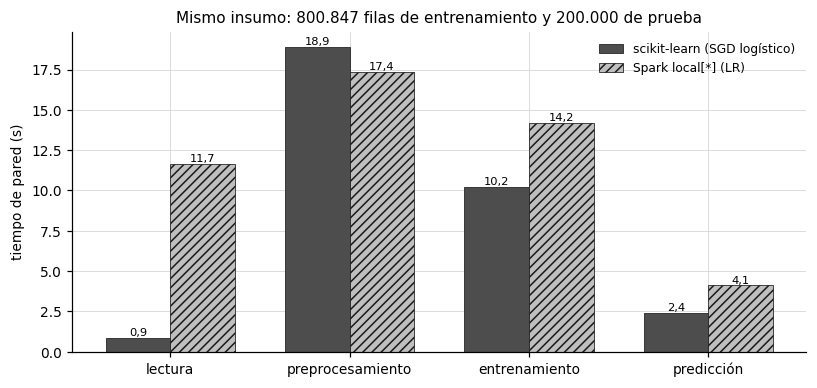

In [4]:
etapas = {"lectura": ["lectura_train", "lectura_test"], "preprocesamiento": ["preprocesamiento_ajuste_y_transform", "preprocesamiento_ajuste", "preprocesamiento_transform"],
          "entrenamiento": ["entrenamiento_sgd", "entrenamiento_lr"], "predicción": ["preprocesamiento_test", "prediccion_sgd", "prediccion_lr"]}
et = pd.read_csv(ART / "benchmarking" / "tiempos_por_etapa.csv")
tot = {env: [et[(et["entorno"] == env) & (et["etapa"].isin(v))]["tiempo_s"].sum() for v in etapas.values()] for env in ("sklearn", "spark")}
fig, ax = new_figure((7.5, 3.6))
x = np.arange(len(etapas)); w = 0.36
for k, (env, nom, col, hat) in enumerate((("sklearn", "scikit-learn (SGD logístico)", "#4d4d4d", ""), ("spark", "Spark local[*] (LR)", "#bfbfbf", "////"))):
    b = ax.bar(x + (k - 0.5) * w, tot[env], width=w, color=col, hatch=hat, edgecolor="#1a1a1a", linewidth=0.5, label=nom)
    for xi, v in zip(x + (k - 0.5) * w, tot[env]):
        ax.text(xi, v, es(v, 1), ha="center", va="bottom", fontsize=7.5)
ax.set_xticks(x); ax.set_xticklabels(list(etapas.keys()))
ax.set_ylabel("tiempo de pared (s)"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Mismo insumo: 800.847 filas de entrenamiento y 200.000 de prueba", fontsize=10)
plt.tight_layout(); plt.show()

**Interpretación.** Con el mismo insumo, el flujo completo de la regresión logística tarda 32,4 s en scikit-learn y 47,3 s en Spark, 1,46 veces más. La mayor diferencia está en la lectura: 0,85 s en scikit-learn frente a 11,7 s en Spark, que incluyen poner los datos en caché y materializarlos con `count()`. El preprocesamiento tarda casi lo mismo (18,9 s y 17,4 s), aunque no hace el mismo trabajo, porque scikit-learn calcula además la frecuencia y el target encoding fuera de pliegue con 5 pliegues. En el entrenamiento, scikit-learn tarda 10,2 s y Spark 14,2 s, y la predicción es de 2,4 s y 4,1 s.

Esto significa que, con 800 mil filas, Spark paga un sobrecosto fijo de coordinación en cada etapa: planificar tareas, serializar entre la JVM y Python y materializar la caché. Ese sobrecosto no se compensa con paralelismo a este tamaño, porque la sección 7.2 mostró que en esta máquina Spark no aprovecha más de unos 2 núcleos.

La tabla siguiente reporta los tiempos de los experimentos principales, cada uno con su volumen de entrenamiento. Las predicciones de scikit-learn se hicieron sobre 202.511 filas y las de Spark sobre las 4.218.938 del día 30.

In [5]:
sk = pd.read_csv(ART / "sklearn" / "runs.csv").query("tier == 2000000")
sp = pd.read_csv(ART / "spark" / "runs.csv")
filas = []
for m, nom in (("mlp", "MLP (50)"), ("histgb", "HistGB"), ("sgd", "SGD (logística)")):
    g = sk[sk["model"] == m]
    filas.append({"entorno": "scikit-learn", "modelo": nom, "filas de entrenamiento": 1601694, "preprocesamiento (s)": np.nan,
                  "entrenamiento (s)": g["fit_time_s"].mean(), "DE entrenamiento (s)": g["fit_time_s"].std(),
                  "predicción (s)": g["predict_time_s"].mean(), "filas de prueba": 202511})
for m, nom, n in (("lr", "LR", 32377421), ("gbt", "GBT", 1000000), ("mlp", "MLP (100)", 300000)):
    g = sp[sp["model"] == m]
    filas.append({"entorno": "Spark local", "modelo": nom, "filas de entrenamiento": n, "preprocesamiento (s)": g["feature_fit_time_s"].mean(),
                  "entrenamiento (s)": g["fit_time_s"].mean(), "DE entrenamiento (s)": g["fit_time_s"].std(),
                  "predicción (s)": g["predict_time_s"].mean(), "filas de prueba": 4218938})
t = pd.DataFrame(filas)
t["filas por segundo (entrenamiento)"] = t["filas de entrenamiento"] / t["entrenamiento (s)"]
tabla(t, d=1, enteros=("filas de entrenamiento", "filas de prueba"))

entorno,modelo,filas de entrenamiento,preprocesamiento (s),entrenamiento (s),DE entrenamiento (s),predicción (s),filas de prueba,filas por segundo (entrenamiento)
scikit-learn,MLP (50),1.601.694,,"330,5","86,6","0,2",202.511,"4.846,3"
scikit-learn,HistGB,1.601.694,,"14,5","5,1","0,8",202.511,"110.145,0"
scikit-learn,SGD (logística),1.601.694,,"28,1","6,4","0,0",202.511,"56.991,2"
Spark local,LR,32.377.421,"166,9","497,1","20,4","44,1",4.218.938,"65.135,4"
Spark local,GBT,1.000.000,"187,9","214,6","37,6","26,5",4.218.938,"4.659,8"
Spark local,MLP (100),300.000,"170,8","1.737,5","51,5","125,9",4.218.938,"172,7"


**Interpretación.** En scikit-learn, el MLP es el modelo más lento, con 330,5 s de entrenamiento en promedio (DE de 86,6 s) y unas 4.800 filas por segundo, frente a 28,1 s de SGD y 14,5 s de HistGB. En Spark, la regresión logística procesa 32,4 millones de filas en 497 s de entrenamiento, más 167 s de preprocesamiento, unas 65.000 filas por segundo, y es el entrenamiento con mayor rendimiento por fila de todo el proyecto. El MLP de Spark tarda 1.737 s con solo 300.000 filas, unas 170 filas por segundo, 28 veces menos que el MLP de scikit-learn. Predecir es barato en todos los casos: menos de un segundo en scikit-learn y entre 26 y 126 s para los 4,2 millones de filas en Spark.

Hay que tener en cuenta que el rendimiento por fila de Spark depende sobre todo del modelo. Con un modelo lineal, cuyo costo por iteración es una agregación del gradiente, Spark procesa el train completo en unos 11 minutos, algo que el pipeline en memoria de scikit-learn no puede hacer en esta máquina (sección 7.4). Con el MLP, la densificación de la entrada (sección 5.3) lo vuelve el modelo más lento por fila de todo el proyecto.

## 9.3 Ablaciones

Todas las ablaciones usan el MLP de scikit-learn con los hiperparámetros afinados, 200.000 filas de train por semilla y las mismas 200.000 filas de validación y de prueba. Se cambia un factor a la vez alrededor de la configuración base, que es la del experimento principal. En cada semilla, todas las variantes usan la misma muestra de entrenamiento y la misma inicialización, así que el contraste con la base es pareado: prueba $t$ pareada, TOST pareado con $\delta = 0{,}01$, tamaño de efecto $d_z = \bar d / s_d$ y corrección de Holm sobre los contrastes. La memoria es la de la matriz de entrenamiento (bytes de los arreglos de la matriz dispersa o densa), y el tiempo se reporta por época y como mediana entre semillas, porque el número de épocas depende de la parada temprana y algunas corridas compartieron la máquina con otros procesos.

In [6]:
nombres = {"base": "base", "solo_hashing": "solo hashing 2^12", "solo_target_encoding": "solo target encoding",
           "solo_frecuencia": "solo frecuencia", "hashing_2^10": "hashing 2^10", "hashing_2^14": "hashing 2^14",
           "hashing_2^16": "hashing 2^16", "sin_cruce": "sin cruce site_id × device_type", "dos_capas_50_50": "dos capas (50, 50)",
           "ponderacion_balanceada": "ponderación balanceada (sobremuestreo ingenuo)",
           "ponderacion_balanceada_val_limpia": "ponderación balanceada (validación limpia)",
           "con_C_y_hora": "con C1, C14–C21 y hora"}
g = runs_abl.assign(s_epoca=runs_abl["fit_time_s"] / runs_abl["n_iter"]).groupby("config").agg(
    auc=("roc_auc", "mean"), de=("roc_auc", "std"), logloss=("log_loss", "mean"), ece=("ece", "mean"),
    columnas=("n_features", "first"), mem=("mem_X_train_mb", "mean"), epocas=("n_iter", "median"), s_epoca=("s_epoca", "median"))
g = g.reindex([c for c in nombres if c in g.index]).reset_index()
g["config"] = g["config"].map(nombres)
tabla(g.rename(columns={"config": "variante", "auc": "ROC AUC", "de": "DE", "logloss": "log loss", "ece": "ECE",
                        "columnas": "columnas", "mem": "matriz train (MB)", "epocas": "épocas (mediana)",
                        "s_epoca": "s por época (mediana)"}), d=4, enteros=("columnas",))

variante,ROC AUC,DE,log loss,ECE,columnas,matriz train (MB),épocas (mediana),s por época (mediana)
base,"0,7256","0,0027","0,4082","0,0113",4.110,"62,5565","20,0000","3,2317"
solo hashing 2^12,"0,7253","0,0004","0,4079","0,0076",4.096,"30,5131","14,0000","3,1255"
solo target encoding,"0,7212","0,0015","0,4096","0,0077",13,"19,8364","13,0000","0,4832"
solo frecuencia,"0,5793","0,0104","0,4506","0,0079",13,"19,8364","7,0000","0,4424"
hashing 2^10,"0,7256","0,0009","0,4081","0,0110",1.038,"62,5360","11,0000","0,6870"
hashing 2^14,"0,7253","0,0016","0,4084","0,0118",16.398,"62,5583","9,0000","10,7421"
hashing 2^16,"0,7243","0,0042","0,4089","0,0107",65.550,"62,5606","11,0000","40,4278"
sin cruce site_id × device_type,"0,7262","0,0019","0,4077","0,0095",4.110,"60,2682","11,0000","3,1907"
"dos capas (50, 50)","0,7258","0,0021","0,4078","0,0100",4.110,"62,5565","11,0000","3,9560"
ponderación balanceada (sobremuestreo ingenuo),"0,6861","0,0061","0,6292","0,2457",4.110,"62,5565","94,0000","5,4659"


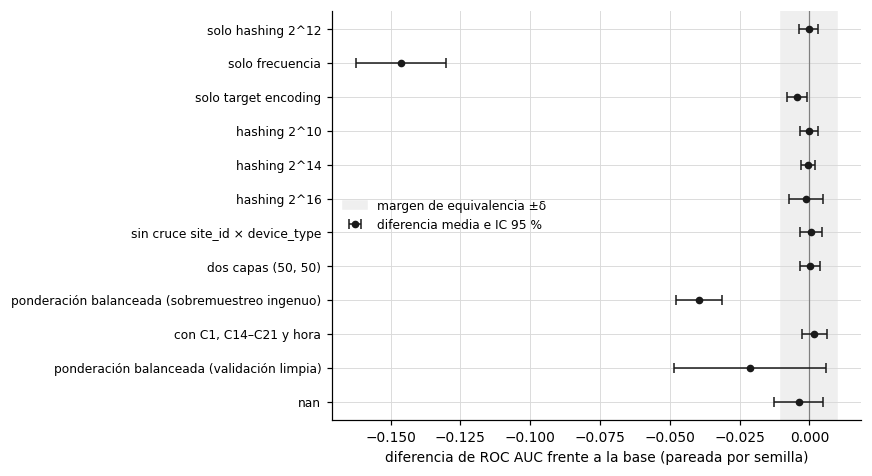

variante,diferencia,IC inf.,IC sup.,d_z,p t pareada,p Holm,p TOST,p TOST Holm,p Shapiro,conclusión
solo hashing 2^12,"-0,0003","-0,0037","0,0032","-0,1023","0,8302","1,0000","0,0007","0,0078","0,0107",equivalente dentro de delta
solo frecuencia,"-0,1463","-0,1624","-0,1302","-11,3002","0,0000","0,0002","1,0000","1,0000","0,0584",diferencia significativa
solo target encoding,"-0,0044","-0,0078","-0,0009","-1,5813","0,0241","0,2410","0,0054","0,0377","0,5151",equivalente dentro de delta
hashing 2^10,"-0,0001","-0,0032","0,0031","-0,0259","0,9565","1,0000","0,0005","0,0057","0,0390",equivalente dentro de delta
hashing 2^14,"-0,0004","-0,0029","0,0022","-0,1740","0,7170","1,0000","0,0002","0,0029","0,9901",equivalente dentro de delta
hashing 2^16,"-0,0013","-0,0074","0,0048","-0,2733","0,5742","1,0000","0,0084","0,0506","0,5661",no concluyente
sin cruce site_id × device_type,"0,0006","-0,0033","0,0046","0,1949","0,6854","1,0000","0,0014","0,0122","0,9944",equivalente dentro de delta
"dos capas (50, 50)","0,0002","-0,0034","0,0038","0,0622","0,8960","1,0000","0,0008","0,0083","0,9690",equivalente dentro de delta
ponderación balanceada (sobremuestreo ingenuo),"-0,0395","-0,0477","-0,0314","-6,0289","0,0002","0,0019","0,9997","1,0000","0,5599",diferencia significativa
"con C1, C14–C21 y hora","0,0018","-0,0028","0,0065","0,4925","0,3326","1,0000","0,0040","0,0323","0,4557",equivalente dentro de delta


In [7]:
c = contr[contr["referencia"] == "base"].copy()
c["variante"] = c["config"].map(nombres)
c = c.iloc[::-1]
fig, ax = new_figure((8, 4.4))
y = np.arange(len(c))
ax.axvspan(-0.01, 0.01, color="#efefef", zorder=0, label="margen de equivalencia ±δ")
ax.axvline(0, color="#808080", linewidth=0.8)
ax.errorbar(c["diferencia_media"], y, xerr=[c["diferencia_media"] - c["ic95_low"], c["ic95_high"] - c["diferencia_media"]],
            fmt="o", color="#1a1a1a", capsize=3, markersize=4, linewidth=1, label="diferencia media e IC 95 %")
ax.set_yticks(y); ax.set_yticklabels(c["variante"], fontsize=8)
ax.set_xlabel("diferencia de ROC AUC frente a la base (pareada por semilla)")
ax.legend(frameon=False, fontsize=8, loc="center left")
plt.tight_layout(); plt.show()
t = c.iloc[::-1][["variante", "diferencia_media", "ic95_low", "ic95_high", "d_z", "p_valor", "p_valor_holm", "p_valor_tost",
                  "p_valor_tost_holm", "shapiro_p_diferencias", "conclusion"]]
tabla(t.rename(columns={"diferencia_media": "diferencia", "ic95_low": "IC inf.", "ic95_high": "IC sup.", "p_valor": "p t pareada",
                        "p_valor_holm": "p Holm", "p_valor_tost": "p TOST", "p_valor_tost_holm": "p TOST Holm",
                        "shapiro_p_diferencias": "p Shapiro", "conclusion": "conclusión"}), d=4)

**Interpretación.** Siete de las doce variantes son equivalentes a la base dentro del margen $\delta = 0{,}01$: el hashing solo (−0,0003), el target encoding solo (−0,0044), el hashing de 2^10 (−0,0001) y de 2^14 (−0,0004), quitar el cruce (+0,0006), la segunda capa (+0,0002) y agregar las columnas C y la hora (+0,0018). En todas ellas la prueba TOST con corrección de Holm rechaza que la diferencia supere $\delta$, con *p* entre 0,003 y 0,038. El hashing de 2^16 tiene una diferencia media de −0,0013, pero su intervalo es más ancho, de −0,0074 a 0,0048, por la semilla 13 (0,7170), y la TOST corregida queda en 0,051, así que es no concluyente. Dos variantes empeoran de forma significativa: la codificación solo por frecuencia, que pierde 0,146 de AUC ($d_z = -11{,}3$, *p* de Holm de 0,0002), y la ponderación balanceada con sobremuestreo ingenuo, que pierde 0,040 (*p* de Holm de 0,0019); las dos variantes corregidas de la ponderación se analizan más adelante. El costo sí cambia mucho entre variantes: el tiempo por época del MLP pasa de 0,69 s con 2^10 a 3,23 s con 2^12, 10,74 s con 2^14 y 40,43 s con 2^16, mientras que la memoria de la matriz de entrenamiento se mantiene en 62,5 MB en las cuatro dimensiones.

Esto significa que, con este modelo y 200.000 filas, la representación ya satura con hashing de 2^10 posiciones y que aumentar la dimensión solo encarece el entrenamiento. La memoria de la matriz no cambia porque una matriz dispersa CSR guarda solo los valores distintos de cero, que son a lo sumo 13 posiciones hasheadas y 14 variables densas por fila, sin importar el número de columnas. El tiempo, en cambio, crece casi en proporción a la dimensión, porque scikit-learn actualiza en cada minilote la matriz de pesos completa de la primera capa, de $d \times 50$ parámetros, con Adam, aunque la entrada sea dispersa: al multiplicar la dimensión por 4, el tiempo por época se multiplica por 3,3 a 4,7. Así mismo, ni el cruce `site_id × device_type` ni la segunda capa aportan, lo que indica que el MLP de una capa ya captura las interacciones útiles, y agregar las columnas anonimizadas y la hora tampoco cambia el resultado de forma relevante. Hay que tener en cuenta que en dos contrastes, el hashing solo y el hashing de 2^10, la prueba de Shapiro-Wilk rechaza la normalidad de las diferencias (*p* de 0,011 y 0,039), aunque con 5 pares su potencia es muy baja; en ambos casos la conclusión de equivalencia se apoya en intervalos que quedan lejos de $\pm\delta$.

Por lo anterior, se opta por recomendar hashing de 2^10 a 2^12 posiciones, una capa oculta y sin cruces explícitos, porque son las configuraciones más baratas sin pérdida de AUC medible. Mantener el modelo principal con 2^12 y cruce es defendible, porque es equivalente a esas variantes dentro de $\delta$, pero no aporta frente a una versión más simple. El hashing de 2^16 no se recomienda: cuesta 12,5 veces más tiempo por época que el de 2^12 y no mejora el AUC en ninguna semilla.

### Ponderación de clases: dos fallas de la parada temprana

`MLPClassifier` no acepta pesos por clase ni por muestra, así que la ponderación se emula sobremuestreando los positivos de train hasta igualar a los negativos, lo que en esperanza equivale a pesos balanceados. La primera variante, la ingenua, sobremuestrea antes de entrenar y deja que `MLPClassifier` separe su 10 % interno de validación para la parada temprana. Al ver sus resultados se agregaron dos variantes corregidas: una separa una validación limpia del 10 % antes de sobremuestrear y conserva la regla de scikit-learn, que se detiene por el accuracy de validación, y la otra usa además el ROC AUC de validación como criterio de parada. La tabla resume las épocas y las métricas de cada semilla.

In [8]:
v = runs_abl[runs_abl["config"].isin(["base", "ponderacion_balanceada", "ponderacion_balanceada_val_limpia",
                                      "ponderacion_balanceada_val_limpia_auc"])].copy()
v["variante"] = v["config"].map({"base": "base", "ponderacion_balanceada": "ingenua",
                                 "ponderacion_balanceada_val_limpia": "validación limpia, parada por accuracy",
                                 "ponderacion_balanceada_val_limpia_auc": "validación limpia, parada por AUC"})
p = v.pivot_table(index="seed", columns="variante", values=["n_iter", "roc_auc"]).round(4)
p.columns = [f"{'épocas' if m == 'n_iter' else 'AUC'}: {c}" for m, c in p.columns]
tabla(p.reset_index().rename(columns={"seed": "semilla"}), d=4, enteros=("semilla",) + tuple(c for c in p.columns if c.startswith("épocas")))
r = v.groupby("variante")[["roc_auc", "log_loss", "ece", "threshold"]].mean().reset_index()
tabla(r.rename(columns={"roc_auc": "ROC AUC", "log_loss": "log loss", "ece": "ECE", "threshold": "umbral F1"}), d=4)

semilla,épocas: base,épocas: ingenua,"épocas: validación limpia, parada por AUC","épocas: validación limpia, parada por accuracy",AUC: base,AUC: ingenua,"AUC: validación limpia, parada por AUC","AUC: validación limpia, parada por accuracy"
13,20,106,21,7,"0,7260","0,6890","0,7143","0,7271"
29,16,59,7,55,"0,7271","0,6948","0,7268","0,6929"
47,21,94,15,62,"0,7271","0,6823","0,7166","0,6879"
71,12,102,8,59,"0,7271","0,6792","0,7264","0,6891"
97,22,73,7,7,"0,7208","0,6851","0,7252","0,7252"


variante,ROC AUC,log loss,ECE,umbral F1
base,"0,7256","0,4082","0,0113","0,2124"
ingenua,"0,6861","0,6292","0,2457","0,5159"
"validación limpia, parada por AUC","0,7218","0,6244","0,2837","0,5502"
"validación limpia, parada por accuracy","0,7044","0,6153","0,2586","0,5362"


**Interpretación.** La base se detiene entre 12 y 22 épocas, y la variante ingenua entre 59 y 106, con un AUC medio de 0,6861, 0,040 menos que la base. Con la validación limpia y la parada por accuracy, el resultado se vuelve bimodal: en las semillas 13 y 97 el entrenamiento se detiene en la época 7 y el AUC (0,7271 y 0,7252) es igual o mayor que el de la base, y en las semillas 29, 47 y 71 sigue entre 55 y 62 épocas y el AUC cae a valores de 0,688 a 0,693. Con la parada por AUC, el entrenamiento dura entre 7 y 21 épocas y el AUC medio es de 0,7218, una diferencia de −0,0038 frente a la base, con IC 95 % de −0,0125 a 0,0049, que no permite afirmar ni diferencia ni equivalencia. En todas las variantes ponderadas la calidad probabilística empeora mucho: el log loss sube unos 0,21 puntos, el ECE pasa de 0,011 a valores de 0,23 a 0,29 y el umbral óptimo para F1 sube de 0,21 a valores de 0,50 a 0,57.

Esto quiere decir que la pérdida de AUC de la variante ingenua no se debe a ponderar las clases, sino a dos fallas de la parada temprana que hacen entrenar de más. La primera es la fuga entre la validación interna y el entrenamiento: con el sobremuestreo previo, copias del mismo positivo caen en ambos lados, y la validación premia memorizarlas. La segunda es el criterio: con entrenamiento balanceado y una validación con la tasa base real, el modelo ubica sus probabilidades alrededor de 0,5 y, con ese umbral, predice clic para una fracción grande de las impresiones; a medida que se sobreajusta a los positivos duplicados tiende a predecir menos positivos en datos nuevos, y como el 83 % de la validación son negativos, el accuracy sube aunque el AUC baje. La evidencia es directa: dentro de la misma variante, todas las corridas que se detienen antes de la época 10 conservan el AUC de la base, y todas las que pasan de 50 épocas lo pierden. El aumento del log loss, en cambio, sí es efecto de la ponderación: un modelo entrenado con clases balanceadas estima probabilidades como si la tasa base fuera 0,5, y se corrige con la regla de Bayes, multiplicando sus *odds* por $\pi/(1-\pi) \approx 0{,}17/0{,}83$.

Por esta razón, lo indicado es no ponderar las clases en este problema. Con la métrica primaria, el AUC, la ponderación no mejora el resultado en ninguna variante, y obliga a recalibrar las probabilidades y a cambiar el umbral. Si se quisiera ponderar, la parada temprana debe hacerse sobre una validación separada antes de sobremuestrear y con un criterio que no dependa de la tasa base, como el AUC o el log loss. Este resultado se reporta completo, con la variante ingenua incluida, porque muestra cómo una decisión de implementación puede producir una conclusión equivocada sobre una técnica.

## 9.4 Respuesta a la pregunta P2 y a la hipótesis H2

La hipótesis H2 sostenía que el hashing con dimensión moderada es comparable a la codificación por frecuencia con una fracción de la memoria. El contraste directo entre ambas estrategias, sobre las mismas columnas, es:

In [9]:
h = contr[contr["referencia"] == "solo_frecuencia"].iloc[0]
print(f"solo hashing − solo frecuencia: {es(h['diferencia_media'])} [{es(h['ic95_low'])}; {es(h['ic95_high'])}], "
      f"d_z = {es(h['d_z'], 2)}, p Holm = {h['p_valor_holm']:.1e}".replace(".", ",") + f"; memoria {es(h['mem_mb_variante'], 1)} MB frente a {es(h['mem_mb_referencia'], 1)} MB")

solo hashing − solo frecuencia: 0,1460 [0,1331; 0,1590], d_z = 14,00, p Holm = 8,1e-05; memoria 30,5 MB frente a 19,8 MB


**Interpretación.** La hipótesis H2 se rechaza en sus dos partes. El hashing solo no es comparable a la frecuencia sola, sino mucho mejor: supera su AUC en 0,146, con IC 95 % de 0,133 a 0,159 y $d_z = 14{,}0$. Tampoco usa una fracción de la memoria: su matriz de entrenamiento ocupa 30,5 MB, frente a 19,8 MB de la frecuencia, 1,5 veces más.

Lo anterior se explica por lo que cada codificación conserva. La frecuencia reemplaza cada categoría por su conteo relativo en train, así que dos sitios o aplicaciones con el mismo número de impresiones quedan indistinguibles aunque tengan tasas de clic muy distintas; el modelo pierde la identidad de la categoría, que es justo lo que predice el clic (sección 8.6). El hashing conserva esa identidad, salvo por las colisiones entre categorías que comparten una posición (sección 3.4); como las frecuencias tienen cola larga (sección 2.6), lo esperable es que una categoría frecuente comparta su posición sobre todo con categorías mucho menos frecuentes, que alteran poco su señal. En memoria, la frecuencia es una matriz densa de 13 columnas, 8 bytes por valor, y el hashing una matriz dispersa con 13 valores por fila que guarda, además de cada valor, su índice de columna; por eso ocupa más aunque tenga 4.096 columnas. El costo del hashing no está en la matriz, sino en los pesos de la primera capa del MLP, que crecen con la dimensión (sección 9.3).

Con base en esto, la respuesta a P2 es que la codificación de las variables de alta cardinalidad determina el desempeño cuando borra la identidad de la categoría, como la frecuencia sola, y casi no lo afecta entre las codificaciones que la conservan: el hashing solo, el target encoding solo y la combinación quedan dentro de $\delta$ entre sí. En costo, el target encoding solo es la opción más barata, con 13 columnas densas y 0,48 s por época, a cambio de 0,0044 de AUC frente a la base, y el hashing de 2^10 es el punto de equilibrio entre costo y desempeño.